In [2]:
import os
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['PYTHONHASHSEED']       = '123'

import random
random.seed(123)

import numpy as np
np.random.seed(123)

import tensorflow as tf
tf.random.set_seed(123)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.callbacks import Callback
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [3]:
fdir = "/kaggle/input/datasets/apriliansyahh/snails/dataBersih"

filepaths = []
labels = []
classlist = os.listdir(fdir)
for klass in classlist:
    classpath = os.path.join(fdir, klass)
    if os.path.isdir(classpath):
        flist = os.listdir(classpath)
        for f in flist:
            if f.lower().endswith(('.png','.jpg','.jpeg','.bmp','.webp')):
                fpath = os.path.join(classpath, f)
                filepaths.append(fpath)
                labels.append(klass)

Fseries = pd.Series(filepaths, name='filepaths')
Lseries = pd.Series(labels, name='labels')

df = pd.concat([Fseries, Lseries], axis=1)
print(df.head())
print(df['labels'].value_counts())

                                           filepaths      labels
0  /kaggle/input/datasets/apriliansyahh/snails/da...  anadara sp
1  /kaggle/input/datasets/apriliansyahh/snails/da...  anadara sp
2  /kaggle/input/datasets/apriliansyahh/snails/da...  anadara sp
3  /kaggle/input/datasets/apriliansyahh/snails/da...  anadara sp
4  /kaggle/input/datasets/apriliansyahh/snails/da...  anadara sp
labels
anadara sp        120
cyclotelina sp    120
gafrarium sp      120
nerita sp         120
pirenella sp      120
polymesoda sp     120
strombus sp       120
turbo sp          120
Name: count, dtype: int64


In [4]:
SEED          = 123
TRAIN_SPLIT   = 0.80      
TEST_SPLIT    = 0.10
BATCH_SIZE    = 32
EPOCHS        = 40
LEARNING_RATE = 0.01
DROPOUT       = 0.5

AUGMENTASI = dict(
    rotation_range   = 10,
    zoom_range       = 0.15,
    horizontal_flip  = True,
    brightness_range = [0.8, 1.2],
    shear_range      = 0.1,
    fill_mode        = 'nearest'
)

In [5]:
train_split = TRAIN_SPLIT
test_split = TEST_SPLIT
dummy_split = test_split / (1 - train_split)

train_df, dummy_df = train_test_split(
    df, 
    train_size=train_split, 
    shuffle=True, 
    random_state=SEED,
    stratify     = df['labels'] 
)
valid_df, test_df = train_test_split(
    dummy_df, 
    train_size=dummy_split, 
    shuffle=True, 
    random_state=SEED,
    stratify     = dummy_df['labels']
)

print('train_df:', len(train_df), ' valid_df:', len(valid_df), ' test_df:', len(test_df))

train_df: 768  valid_df: 96  test_df: 96


In [ ]:
print("=" * 50)
print("DISTRIBUSI DATA PER KELAS")
print("=" * 50)

print("\nTrain Set:")
print(train_df['labels'].value_counts())

print("\nValidation Set:")
print(valid_df['labels'].value_counts())

print("\nTest Set:")
print(test_df['labels'].value_counts())

print("\n" + "=" * 50)
print("TOTAL PER SET:")
print(f"Train      : {len(train_df)} gambar")
print(f"Validation : {len(valid_df)} gambar")
print(f"Test       : {len(test_df)} gambar")
print(f"Total      : {len(df)} gambar")
print("=" * 50)

In [6]:
height     = 224
width      = 224
channels   = 3
batch_size = BATCH_SIZE

img_shape  = (height, width, channels)
img_size   = (height, width)


length = len(test_df)
test_batch_size = sorted([int(length/n) for n in range(1, length+1)
                          if length % n == 0 and length/n <= 80], reverse=True)[0]
test_steps = int(length / test_batch_size)
print('test batch size:', test_batch_size, ' test steps:', test_steps)


train_gen_flow = ImageDataGenerator(
    preprocessing_function = preprocess_input,
    **AUGMENTASI
)

val_test_gen_flow = ImageDataGenerator(preprocessing_function=preprocess_input)


train_gen = train_gen_flow.flow_from_dataframe(
    train_df,
    x_col       = 'filepaths',
    y_col       = 'labels',
    target_size = img_size,
    class_mode  = 'categorical',
    color_mode  = 'rgb',
    shuffle     = True,
    batch_size  = batch_size,
    seed        = SEED
)

valid_gen = val_test_gen_flow.flow_from_dataframe(
    valid_df,
    x_col       = 'filepaths',
    y_col       = 'labels',
    target_size = img_size,
    class_mode  = 'categorical',
    color_mode  = 'rgb',
    shuffle     = False,
    batch_size  = batch_size
)

test_gen = val_test_gen_flow.flow_from_dataframe(
    test_df,
    x_col       = 'filepaths',
    y_col       = 'labels',
    target_size = img_size,
    class_mode  = 'categorical',
    color_mode  = 'rgb',
    shuffle     = False,
    batch_size  = test_batch_size
)

classes     = list(train_gen.class_indices.keys())
class_count = len(classes)
print('Jumlah kelas :', class_count)
print('Kelas        :', classes)

test batch size: 48  test steps: 2
Found 768 validated image filenames belonging to 8 classes.
Found 96 validated image filenames belonging to 8 classes.
Found 96 validated image filenames belonging to 8 classes.
Jumlah kelas : 8
Kelas        : ['anadara sp', 'cyclotelina sp', 'gafrarium sp', 'nerita sp', 'pirenella sp', 'polymesoda sp', 'strombus sp', 'turbo sp']


In [ ]:
def show_image_samples(dframe):
    # Generator terpisah, supaya urutan batch data latih untuk training tidak ikut bergeser
    flow = train_gen_flow.flow_from_dataframe(
        dframe, x_col='filepaths', y_col='labels', target_size=img_size,
        class_mode='categorical', color_mode='rgb', shuffle=True, batch_size=25, seed=1)
    classes = list(flow.class_indices.keys())
    images, labels = next(flow)
    plt.figure(figsize=(25, 25))
    r = min(25, len(labels))
    for i in range(r):
        plt.subplot(5, 5, i + 1)
        plt.imshow((images[i] + 1) / 2)      # balikkan [-1,1] -> [0,1] hanya untuk tampilan
        index = np.argmax(labels[i])
        plt.title(classes[index], color='blue', fontsize=12)
        plt.axis('off')
    plt.show()

show_image_samples(train_df)

In [7]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

base_model = tf.keras.applications.MobileNetV2(
    include_top = False,
    weights     = "imagenet",
    input_shape = (224, 224, 3)
)
base_model.trainable = False
base_model.summary()


model_name = 'MobileNetV2'
print("Building model with", base_model.name)

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(rate=DROPOUT),
    tf.keras.layers.Dense(class_count, activation='softmax')
])

model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss      = 'categorical_crossentropy',
    metrics   = ['accuracy']
)

model.summary()

I0000 00:00:1793777142.379169     110 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793777142.383209     110 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

... (3 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,268,232 (8.65 MB)

 Trainable params: 10,248 (40.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [8]:
class BestWeights(Callback):
    """Simpan bobot pada epoch dengan val_loss terendah (tanpa EarlyStopping, semua epoch dijalankan)."""
    def __init__(self):
        super().__init__()
        self.best, self.best_epoch, self.n, self.snap = np.inf, 0, 0, None
    def on_epoch_end(self, epoch, logs=None):
        self.n += 1
        v = (logs or {}).get('val_loss')
        if v is not None and v < self.best:
            self.best, self.best_epoch = v, self.n
            self.snap = [(w, w.numpy()) for w in self.model.variables]
    def restore(self):
        for w, val in self.snap:
            w.assign(val)


best_cb = BestWeights()

history = model.fit(
    x               = train_gen,
    epochs          = EPOCHS,
    validation_data = valid_gen,
    callbacks       = [best_cb]
)

best_cb.restore()     # kembali ke bobot epoch terbaik
print(f'Epoch terbaik: {best_cb.best_epoch} | val_loss: {best_cb.best:.3e}')

Epoch 1/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 282s 11s/step - accuracy: 0.8477 - loss: 0.4499 - val_accuracy: 0.9896 - val_loss: 0.0476
Epoch 2/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.9870 - loss: 0.0485 - val_accuracy: 0.9896 - val_loss: 0.0136
Epoch 3/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.9909 - loss: 0.0182 - val_accuracy: 1.0000 - val_loss: 0.0021
Epoch 4/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.9922 - loss: 0.0228 - val_accuracy: 0.9896 - val_loss: 0.0123
Epoch 5/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 55s 2s/step - accuracy: 0.9974 - loss: 0.0061 - val_accuracy: 1.0000 - val_loss: 0.0035
Epoch 6/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.9961 - loss: 0.0105 - val_accuracy: 1.0000 - val_loss: 0.0021
Epoch 7/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.9987 - loss: 0.0045 - val_accuracy: 1.0000 - val_loss: 0.0024
Epoch 8/40
24/24 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.9974 - loss: 0.0094 - val_accuracy: 1.0000 - val_los

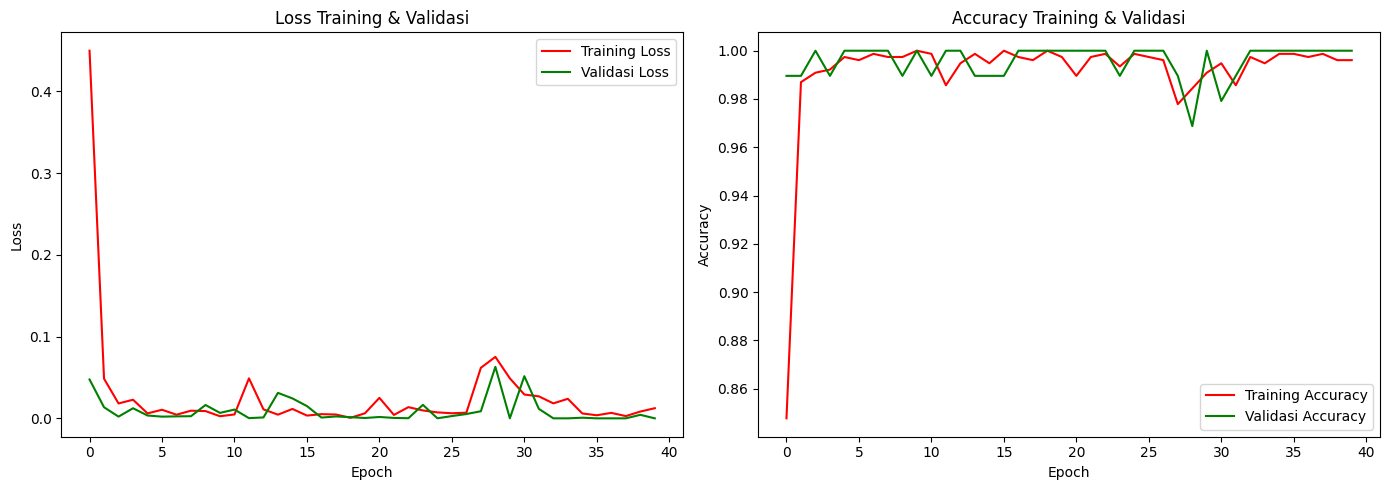

In [9]:
def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Loss
    axes[0].plot(history.history['loss'], 
                 label='Training Loss', color='red')
    axes[0].plot(history.history['val_loss'], 
                 label='Validasi Loss', color='green')
    axes[0].set_title('Loss Training & Validasi')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    
    # Accuracy
    axes[1].plot(history.history['accuracy'], 
                 label='Training Accuracy', color='red')
    axes[1].plot(history.history['val_accuracy'], 
                 label='Validasi Accuracy', color='green')
    axes[1].set_title('Accuracy Training & Validasi')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()

plot_history(history)

In [11]:
def print_info(test_gen, preds, print_code, save_dir, subject):
    class_dict = test_gen.class_indices
    labels     = test_gen.labels
    file_names = test_gen.filenames
    error_list   = []
    true_class   = []
    pred_class   = []
    prob_list    = []
    new_dict     = {}
    error_indices= []
    y_pred       = []
    for key, value in class_dict.items():
        new_dict[value] = key
    classes      = list(new_dict.values())
    dict_as_text = str(new_dict)
    dict_name    = subject + '-' + str(len(classes)) + '.txt'
    dict_path    = os.path.join(save_dir, dict_name)
    with open(dict_path, 'w') as x_file:
        x_file.write(dict_as_text)
    errors = 0
    for i, p in enumerate(preds):
        pred_index = np.argmax(p)
        true_index = labels[i]
        if pred_index != true_index:
            error_list.append(file_names[i])
            true_class.append(new_dict[true_index])
            pred_class.append(new_dict[pred_index])
            prob_list.append(p[pred_index])
            error_indices.append(true_index)
            errors = errors + 1
        y_pred.append(pred_index)
    if print_code != 0:
        if errors > 0:
            r = errors if print_code > errors else print_code
            msg = '{0:^28s}{1:^28s}{2:^28s}{3:^16s}'.format('Filename', 'Predicted Class', 'True Class', 'Probability')
            print_in_color(msg, (0,255,0), (55,65,80))
            for i in range(r):
                split1 = os.path.split(error_list[i])
                split2 = os.path.split(split1[0])
                fname  = split2[1] + '/' + split1[1]
                msg    = '{0:^28s}{1:^28s}{2:^28s}{3:4s}{4:^6.4f}'.format(fname, pred_class[i], true_class[i], ' ', prob_list[i])
                print_in_color(msg, (255,255,255), (55,65,60))
        else:
            msg = 'With accuracy of 100 % there are no errors to print'
            print_in_color(msg, (0,255,0), (55,65,80))
    if errors > 0:
        plot_bar   = []
        plot_class = []
        for key, value in new_dict.items():
            count = error_indices.count(key)
            if count != 0:
                plot_bar.append(count)
                plot_class.append(value)
        fig = plt.figure()
        fig.set_figheight(len(plot_class)/3)
        fig.set_figwidth(10)
        for i in range(0, len(plot_class)):
            plt.barh(plot_class[i], plot_bar[i])
            plt.title('Errors by Class on Test Set')
        plt.show()
    y_true = np.array(labels)
    y_pred = np.array(y_pred)
    if len(classes) <= 30:
        cm     = confusion_matrix(y_true, y_pred)
        length = len(classes)
        fig_width  = 8 if length < 8 else int(length * .5)
        fig_height = 8 if length < 8 else int(length * .5)
        plt.figure(figsize=(fig_width, fig_height))
        sns.heatmap(cm, annot=True, vmin=0, fmt='g', cmap='Blues', cbar=False)
        plt.xticks(np.arange(length)+.5, classes, rotation=45)
        plt.yticks(np.arange(length)+.5, classes, rotation=0)
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.title("Confusion Matrix")
        plt.show()
    clr = classification_report(y_true, y_pred, target_names=classes)
    print("Classification Report:\n----------------------\n", clr)

In [12]:
save_dir = '/kaggle/working/'
subject  = 'moluska'

acc = model.evaluate(
    test_gen,
    batch_size  = test_batch_size,
    verbose     = 1,
    steps       = test_steps,
    return_dict = False
)[1] * 100

print(f'Accuracy pada test set: {acc:5.2f} %')

save_id  = str(model_name + '-' + subject + '-' + str(acc)[:str(acc).rfind('.')+3] + '.keras')
save_loc = os.path.join(save_dir, save_id)
model.save(save_loc)
print(f'Save model: {save_id}')

2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 1.0000 - loss: 1.5340e-04
Accuracy pada test set: 100.00 %
Save model: MobileNetV2-moluska-100.0.keras


2/2 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step


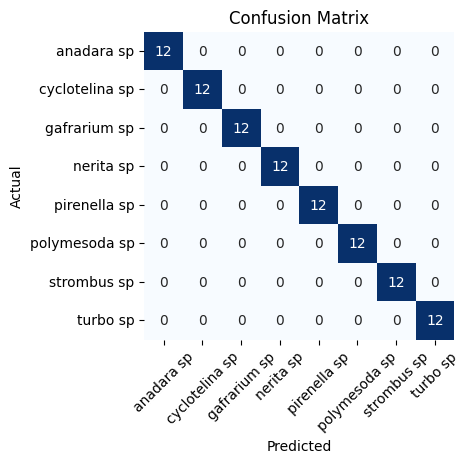

Classification Report:
----------------------
                 precision    recall  f1-score   support

    anadara sp       1.00      1.00      1.00        12
cyclotelina sp       1.00      1.00      1.00        12
  gafrarium sp       1.00      1.00      1.00        12
     nerita sp       1.00      1.00      1.00        12
  pirenella sp       1.00      1.00      1.00        12
 polymesoda sp       1.00      1.00      1.00        12
   strombus sp       1.00      1.00      1.00        12
      turbo sp       1.00      1.00      1.00        12

      accuracy                           1.00        96
     macro avg       1.00      1.00      1.00        96
  weighted avg       1.00      1.00      1.00        96



In [13]:
print_code = 0
preds      = model.predict(test_gen)
print_info(test_gen, preds, print_code, save_dir, subject)

In [14]:
from sklearn.metrics import classification_report
import numpy as np

# ----------------------------------------------------
# 1. Ambil prediksi & label asli dari test set
# ----------------------------------------------------
y_true = np.array(test_gen.labels)
y_pred = np.argmax(preds, axis=1)

class_dict   = test_gen.class_indices
idx_to_class = {v: k for k, v in class_dict.items()}
classes      = [idx_to_class[i] for i in range(len(class_dict))]

# ----------------------------------------------------
# 2. Classification report dalam bentuk dict
# ----------------------------------------------------
report = classification_report(
    y_true, y_pred,
    target_names=classes,
    output_dict=True
)

overall_accuracy = report['accuracy']

classes_metrics = {}
for cls in classes:
    classes_metrics[cls] = {
        'precision': round(report[cls]['precision'], 4),
        'recall':    round(report[cls]['recall'], 4),
        'f1':        round(report[cls]['f1-score'], 4),
        'support':   int(report[cls]['support'])
    }

# ----------------------------------------------------
# 3. Best epoch (berdasarkan val_loss terendah)
# ----------------------------------------------------
val_losses   = history.history['val_loss']
val_accs     = history.history['val_accuracy']
train_accs   = history.history['accuracy']
train_losses = history.history['loss']

best_idx = int(np.argmin(val_losses))

best_epoch_info = {
    'epoch':          best_idx + 1,
    'val_accuracy':   round(val_accs[best_idx], 4),
    'val_loss':       round(val_losses[best_idx], 5),
    'train_accuracy': round(train_accs[best_idx], 4),
    'train_loss':     round(train_losses[best_idx], 4)
}

# ----------------------------------------------------
# 4. Gabungkan & simpan ke .txt
# ----------------------------------------------------
metrics_summary = {
    'accuracy':   round(overall_accuracy, 4),
    'classes':    classes_metrics,
    'best_epoch': best_epoch_info
}

save_dir    = '/kaggle/working/'
output_path = save_dir + 'klasifikasi_metrics.txt'

with open(output_path, 'w') as f:
    f.write(str(metrics_summary))

print(f"Metrics disimpan ke: {output_path}")
print(metrics_summary)

Metrics disimpan ke: /kaggle/working/klasifikasi_metrics.txt
{'accuracy': 1.0, 'classes': {'anadara sp': {'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'support': 12}, 'cyclotelina sp': {'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'support': 12}, 'gafrarium sp': {'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'support': 12}, 'nerita sp': {'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'support': 12}, 'pirenella sp': {'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'support': 12}, 'polymesoda sp': {'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'support': 12}, 'strombus sp': {'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'support': 12}, 'turbo sp': {'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'support': 12}}, 'best_epoch': {'epoch': 37, 'val_accuracy': 1.0, 'val_loss': 0.0, 'train_accuracy': 0.9974, 'train_loss': 0.0067}}
